# Introduction to RAG

**Retrieval-augmented generation (RAG)** enhances the reliability of generative AI models by integrating factual information retrieved from a knowledge base. A RAG architecture can be used to turn a large language model (LLM) into a knowledge assistant, accessing locally hosted, specialized data to deliver accurate and context-aware responses.

This technique has become state of the art across our defense and intelligence communities because public foundation models do not include private or sensitive national security data. RAG architectures enable you to ask quesions about your own data while benefitting from the inference capabilities of foundational LLMs.

In this notebook, we will build a simple retrieval augmented generation (RAG) application. This application will make use of an OCR capability to extract text from unstructured PDF documents, and then apply the NVIDIA NIM and NeMo Retriever components to identify the most relevant documents and information related to the user's query to formulate a coherent LLM response.

We loosely base this notebook off the [Reranking Technical Blog](https://developer.nvidia.com/blog/enhancing-rag-pipelines-with-re-ranking/). In this notebook, we will build a simple retrieval augmented generation (RAG) application. This application will:
1. Use [unstructured.io](https://github.com/Unstructured-IO/unstructured) to perform OCR (Optical Character Recognition) to extract text from unstructured PDF documents
1. Use [Langchain](https://github.com/langchain-ai/langchain) to load the extracted text into a vector database for fast semantic retrieval
1. Accurately answer user queries about these documents by applying the following components:
   * LLM Inference NIM with [llama-3.1-8b-instruct](https://catalog.ngc.nvidia.com/orgs/nvidia/teams/nemo/models/llama-3_1-8b-nemo)
   * NeMo Retriever Embedding NIM with [llama-3.2-nv-embedqa-1b-v2](https://build.nvidia.com/nvidia/llama-3_2-nv-rerankqa-1b-v2)
   * NeMo Retriever Reranker NIM with [llama-3.2-nv-rerankqa-1b-v2](https://build.nvidia.com/nvidia/llama-3_2-nv-embedqa-1b-v2)

Retrieval Augmented Generation (RAG) can be explained as shown in the following graphic:
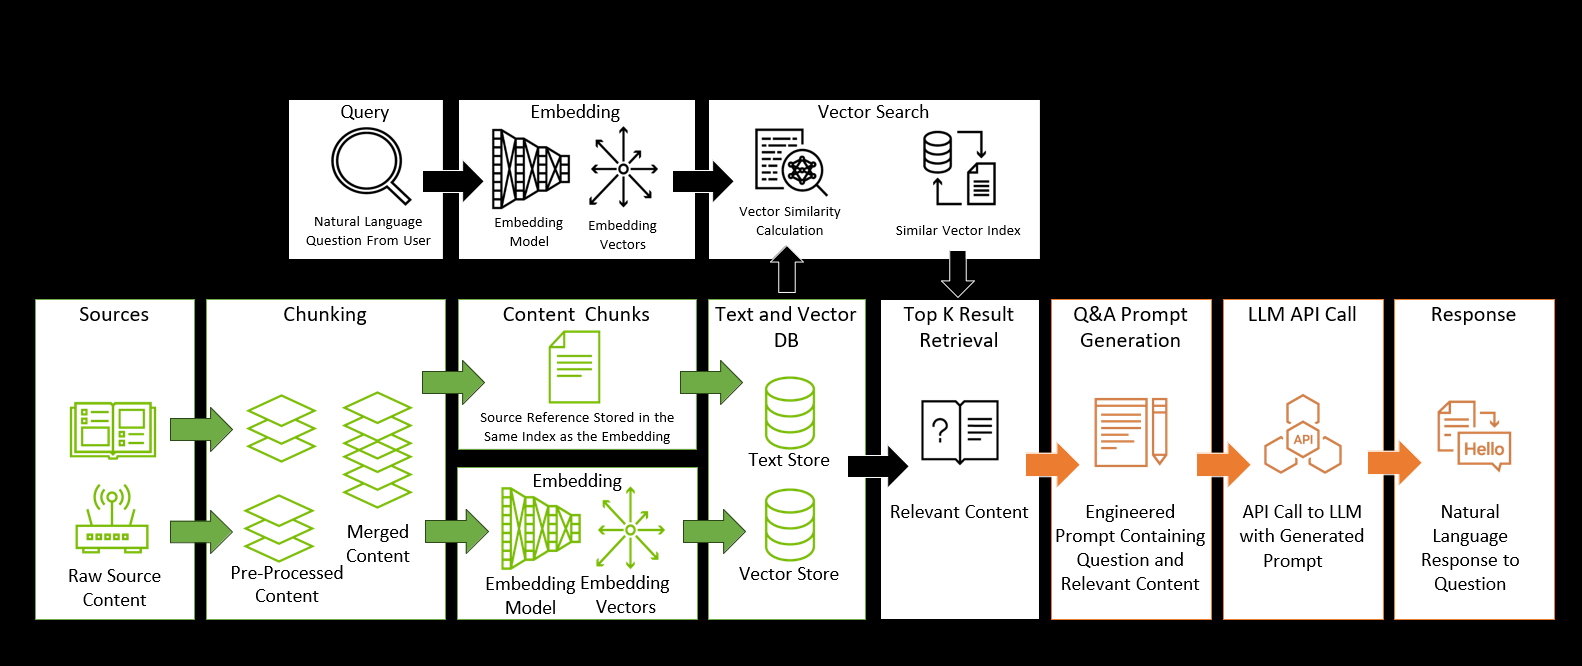

This notebook builds upon concepts learned in the Introduction to NIM and LoRA finetuning notebooks.

**Notebook Requirements**:
* Access to a two NVIDIA GPUs (A30, A100, H100, L40S, A40)
* Access to build.nvidia.com - After the lab, [sign up for access to the NVIDIA NGC](https://ngc.nvidia.com/) and [build.nvidia.com](https://build.nvidia.com/) to access the models used in this lab.
* Docker
* Langchain
* Notebook is designed to be run from host system, and not within docker container.


# Environment Setup

In [ ]:
# Setup Environment
from dotenv import load_dotenv
import os

# Load the .env file
load_dotenv('./docker/.env', override=True)

print(f"NGC_API_KEY for lab use only     : {os.getenv('NGC_API_KEY')}")
print(f"NVIDIA_API_KEY for lab use only  : {os.getenv('NVIDIA_API_KEY')}")
print(f"Current working dir              : { os.getcwd() }")
print(f"PROJECT_DIR for lab              : {os.getenv('PROJECT_DIR')}")
print(f"LOCAL_NIM_CACHE for lab          : {os.getenv('LOCAL_NIM_CACHE')}")
print(f"locally hosted model for lab     : {os.getenv('NIM_SERVED_MODEL_NAME')}")

In [ ]:
# Stop all prior running containers 
!scripts/stop_containers.sh

## Deploy the NIMs locally 
Here will deploy the embedding and reranking NIMs locally run a basic RAG pipeline inference as shown above.  For convenience we have encoded this setup in docker compose yaml files.  This will allow us to run the NIMs locally on our A30/A40 GPUs and beyond.  

Note your environment needs to perform docker login to nvcr.io as follows.   This is taken care of for you in the launchpad environment
```
docker login nvcr.io

Username: $oauthtoken
Password: NGC_CLI_API_KEY
```


If you want to see the configuration, see the [docker-compose.yml](docker/docker-compose.yaml) file. 

In [ ]:
# Start only embed and reranker services 

os.chdir('./docker')
!docker compose up -d nim_embed nim_reranker nim_llama_8b
print("waiting 30 seconds to start")
!sleep 30 # wait for services to start
!docker compose ps
os.chdir('..')
# consumes ~16GB GPU RAM

Lets inspect the models we just loaded. For full specification of the API see https://docs.nvidia.com/nim/large-language-models/latest/api-reference.html

In [ ]:
!docker compose -f docker/docker-compose.yaml ps 
# Setup Base URL variables for use with the rest of the notebook
LLM_URL    = "http://localhost:9990/v1"
RERANK_URL = "http://localhost:9991/v1"
EMBED_URL  = "http://localhost:9992/v1"

#LLM
!curl -X 'GET' {LLM_URL}'/models' |jq
#reranker
!curl -X 'GET' {RERANK_URL}'/models' |jq
#embed
!curl -X 'GET' {EMBED_URL}'/models' |jq

In [ ]:
# Setup MODEL Name variables that we will use for the rest of the lab
LLM_MODEL    = os.getenv('NIM_SERVED_MODEL_NAME')
EMBED_MODEL  = "nvidia/llama-3.2-nv-embedqa-1b-v2"
RERANK_MODEL = "nvidia/llama-3.2-nv-rerankqa-1b-v2"
# NVDEV_LLM_MODEL="nvdev/meta/llama-3.1-8b-instruct"

# Data Preparation 

We will need to pre-process the documents in our archive so that they are retrievable. For our PDF documents, this means we will need to extract the text from the PDF documents and store the text in manageable "chunks" in preparation for the embedding process.

Below, we use the https://docs.unstructured.io/ OCR and langchain frameworks to pre-process the documents.

In [ ]:
# Setup Base Configuration and Perform Health Check
import requests
import json
from typing import Dict, Any

#IPADDRESS = "0.0.0.0" #Replace this with the correct IP address for the rag-server
IPADDRESS = "127.0.0.1"
RAG_PORT = "8086"
BASE_URL = f"http://{IPADDRESS}:{RAG_PORT}"  # Replace with your rag-server URL

# a helper method to print text during asynchronous functions
def print_response(response: requests.Response):
    """Helper to print API response."""
    print(f"Status Code: {response.status_code}")
    try:
        print(json.dumps(response.json(), indent=2))
    except json.JSONDecodeError:
        print(response.text)

In [ ]:
# Use langchain FileSytemBlobLoader to load the markdown files
from unstructured.partition.pdf import partition_pdf
from langchain_core.documents import Document
from glob import glob

corpus_documents = []

pdfs_path = os.getenv('PROJECT_DIR') + '/data/*.pdf'

print("Now parsing PDF data using OCR. This will take about 6 minutes...")
for filename in glob(pdfs_path):
    file_chunks = [str(chunk) for chunk in partition_pdf(filename=filename, url=None)]

    #Print the first 500 parsed characters of each doc
    print(f"Parsed {filename=}:")
    print(f"{chr(10).join(file_chunks):.500}")
    
    doc = Document(page_content=str(file_chunks), metadata={"source": filename})
    corpus_documents.append(doc)



In [ ]:
# Cache the results
import pickle
cache_file = os.path.join(os.getenv('PROJECT_DIR'), 'data', 'corpus_documents.pkl')
print(f"Caching corpus_documents to: {cache_file}")
with open(cache_file, 'wb') as f:
    pickle.dump(corpus_documents, f)

In [ ]:
#Load the cached results
with open(cache_file, 'rb') as f:
    corpus_documents = pickle.load(f)


**While we are waiting for the data to load, we will have a look at the case study for this laboratory**

# Use Case: The Roswell Case Study
We  will demonstrate how a RAG pipeline can improve the quality of results by drawing on your mission data. In this use case, we will draw upon witness accounts from the National Archive Catalog related to the Roswell Report. 

**Background on the Roswell Report:**
* The 1947 Roswell incident investigated claims of a crashed unidentified flying object (UFO) near Roswell, New Mexico
* The "Roswell Report" refers to a collection of government records compiled by the U.S. Air Force regarding this incident
* The report ultimately concluded that the debris recovered from the crash was from a high-altitude weather balloon used in a secret military project called "Project Mogul" and not an alien spacecraft, as had been popularized in UFO lore.
* Project Mogul was a Top Secret project by the US Army Air Forces involving microphones on high-altitude balloons to detect sound waves generated by Soviet atomic bomb tests
* The Air Force released the Roswell Report in 1994 following a request from the General Accounting Office (GAO) to investigate the claims surrounding the Roswell incident. 
* While the official report concludes that the incident was not related to extraterrestrials, many UFO enthusiasts continue to believe the government is covering up evidence of an alien crash.

**Your Mission, should you choose to accept it!**
* You will be serving as an analyst/investigator in 1994 tasked to report on this case.
* Your analysis will be based on actual witness statements associated with the Roswell Report.
* You will develop a RAG-based AI system that can assist you in summarizing and analyzing these statements


**Witness Statements (in /data folder)**

* Coltman Statement
* Gildenberg Statement
* Spilhaus Statement
* Trakowski Statement 

**Check the Text Extractor**

Below you can see that all the documents in the /data directory have been pre-processed and are now ready for the embedding process.

In [ ]:
for doc in corpus_documents:
    print(doc.metadata['source'])
    print(f"{len(doc.page_content)} characters")
    print(str(doc)[:500])

# Split Text from Source Document into Chunks

Before loading text into our vector database, it's important to pay attention to the chunk size. Setting the right chunk size is critical for RAG performance, as much of a RAG pipeline’s success is based on the retrieval step finding the right context for generation. The retrieval step typically examines smaller chunks of the original text rather than all documents.

The entire prompt (retrieved chunks plus the user query) must fit within the LLM’s context window. Don’t specify chunk sizes too big and balance them out with the estimated query size. Experiment with different chunk sizes, but typical values should be 128-512 tokens, depending on the LLM.

In [ ]:
from langchain_text_splitters import RecursiveCharacterTextSplitter
text_splitter = RecursiveCharacterTextSplitter(chunk_size=100, chunk_overlap=50)
document_texts = text_splitter.split_documents(corpus_documents)

In [ ]:
print(len(document_texts))
# Print a sample of the processed document
document_texts[50].page_content

In [ ]:
# Lets look at a histrogram of the length of the text chunks created by the text splitter
import matplotlib.pyplot as plt
plt.hist([len(str(text)) for text in document_texts], bins=20)
plt.xlabel('Length of text chunk')
plt.ylabel('Number of text chunks')
plt.title('Histogram of the length of the text chunks page content')

# Generate Embeddings

Next, generate embeddings using NVIDIA AI Foundation endpoints and save the embeddings to an offline vector store in the /embed directory for future re-use.

For application deployments, we recommend using a vector database such as Milvus for persistent storage of your RAG knowledge base.

For more detail on NVIDIA Embeddings via langchain, see the [NVIDIA Embeddings Documentation](https://python.langchain.com/v0.2/docs/integrations/text_embedding/nvidia_ai_endpoints/)

In [ ]:
from langchain_nvidia_ai_endpoints import NVIDIAEmbeddings
from langchain_community.vectorstores import FAISS
embedder = NVIDIAEmbeddings(base_url=EMBED_URL, model=EMBED_MODEL)
print([emb.id for emb in embedder.get_available_models()])
print(f"For embedding using {EMBED_MODEL}")

query = "Summarize the Statements from Coltman, Gildenberg, Spilhaus, and Trakowski related to the Roswell Case"
embedder.embed_query(query)[:10]

Here you can see the available models that we can use.  For this lab we will make use of the Llama 3.2 embedding model.  This model is also accessible via build.nvidia.com and can be locally download (we show this later).

We run the embedder so we can print a sample output: as expected, our embedder creates an array of floats between 0 and 1. This is known as an embedding, aka a vector that can be stored in a vector database.

Next, we will initialize the connection to our in memory FAISS vector database. 

In [ ]:
# Local NIM version ->
print(f"For embedding using {EMBED_MODEL}")
db = FAISS.from_documents(document_texts, embedder)

After the completion of this step, we have our embeddings stored in GPU memory and ready for use in our RAG pipeline.

# Create Base Retriever
In this lab we will create 2 retrievers.
In this section, we'll make a simple retriever that fetches 5 similar documents for question and answer generation.

Later, we'll make a reranking retriever that fetches many similar documents and pares down the result to the 5 best most relavant chunks.

In [ ]:
# Create a retriever and fetch the top 5 similar documents for a query
base_retriever = db.as_retriever(search_kwargs={"k": 5},search_type="mmr")

In [ ]:
import json
# Basic test of the retreiver
query = "Summarize the Statements from Coltman, Gildenberg, Spilhaus, and Trakowski related to the Roswell Case"
docs = base_retriever.invoke(query)
print(f"Number of documents returned : {len(docs)}")
# Print the first document
print(json.dumps(docs[0].to_json(), indent=4))

# Generating an Answer
Purpose: This endpoint generates an AI response to a given user message. The system message is specified in the prompts.yaml file. This API retrieves the relevant chunks related to the query from knowledge base, adds them as part of the LLM prompt and returns a streaming response. It supports parameters like temperature, top_p, knowledge base usage, and also generates based on the specified vector collection.

In [ ]:
from langchain.chains import RetrievalQA
from langchain_nvidia_ai_endpoints import ChatNVIDIA

query = "Explain how Project Mogul is related to the Roswell incident?"

llm=ChatNVIDIA(model=LLM_MODEL,
                   base_url=LLM_URL, 
                   temperature=0)

simple_llm_retriever_chain = RetrievalQA.from_chain_type(
    llm=llm, retriever=base_retriever
) 

result = simple_llm_retriever_chain.invoke({"query": query})

print(query)
print(result.get("result"))

*Let's try a different query to see just how how much prompt engineering matters!*

In [ ]:
query = (
    "You are an investigator reviewing the provided documents, which are all related to the Roswell Case Study. "
    "Explain, based on the accounts provided by Coltman, Gildenberg, Spilhaus, and Trakowski how individuals unfamiliar with this case might think that there were UFOs and aliens at the New Mexico Roswell site"
    "Elaborate on the possible misconceptions and explain as if you were talking to a scientific expert."
)

result = simple_llm_retriever_chain.invoke({"query": query})

print(query)
print(result.get("result"))

# Add a re-ranking step

![build.nvidia.com](images/rag_workflow.png)

Here we will look at the exact same query, but now add a reranking step as part of our workflow.  This is a GPU-accelerated model optimized for providing a probability score that a given passage contains the information to answer a question. This re-ranks the previously fetched chunks according to which is most relevant using the same query.

You use the NIM as input to the LangChain contextual compression retriever, which improves retrieval by compressing and filtering documents based on the query context before returning them.

In [ ]:
from langchain_nvidia_ai_endpoints import NVIDIARerank
from langchain.retrievers.contextual_compression import ContextualCompressionRetriever
 
# @ https://api.python.langchain.com/en/latest/retrievers/langchain.retrievers.contextual_compression.ContextualCompressionRetriever.html

# Create a new retriever that fetches 45 documents
rr_vectordb_retriever = db.as_retriever(search_kwargs={"k": 45})
# ?NVIDIARerank
# reranker = NVIDIARerank(top_n=5)

# Use local reranking NIM
reranker = NVIDIARerank(top_n=5, 
                        model=RERANK_MODEL ,
                        base_url=RERANK_URL)

compression_retriever = ContextualCompressionRetriever(
    base_compressor=reranker, base_retriever=rr_vectordb_retriever,search_type="mmr"
)

reranked_chunks = compression_retriever.invoke(query)

In [ ]:
print(len(reranked_chunks))
# Print the first document
print(json.dumps(reranked_chunks[0].to_json(),indent=4))

# Connect Reranker to a RAG Pipeline
![build.nvidia.com](images/rr_connect_to_rag.png)

In addition to using re-ranking independently, you can add it to a RAG pipeline to further enhance responses by ensuring that they use the most relevant chunks for augmenting the original query.

In the cell below, we add our reranker retriever to our LLM chain to perform Q/A over a pdf.

## Why use Embedding + Reranking in RAG Pipelines?

A simple retrieval pipeline can use **an embedding model and a vector database**. The user's query is embedded to create a vector, which is used to query the vector database and return a collection of relevant matches.

An advanced retrieval pipeline can do this in two stages. After the vector database query, a **reranker** is used to further refine those query results. This is called **two-stage retrieval**. Let's look at how this can be implemented in Langchain.

In [ ]:
from langchain_nvidia_ai_endpoints import NVIDIARerank
from langchain.retrievers.contextual_compression import ContextualCompressionRetriever
 
# @ https://api.python.langchain.com/en/latest/retrievers/langchain.retrievers.contextual_compression.ContextualCompressionRetriever.html

# Create a new retriever that fetches 45 documents
retriever_stage_1 = db.as_retriever(search_kwargs={"k": 45},search_type="mmr")

# Use local reranking NIM
retriever_stage_2 = NVIDIARerank(top_n=5, 
                        model=RERANK_MODEL,
                        base_url=RERANK_URL)

two_stage_retriever = ContextualCompressionRetriever(
    base_retriever=retriever_stage_1, base_compressor=retriever_stage_2, search_type="mmr"
)

reranked_chunks = two_stage_retriever.invoke(query)

In [ ]:
print(len(reranked_chunks))
# Print the first document
print(json.dumps(reranked_chunks[0].to_json(),indent=4))

# Connect Reranker to a RAG Pipeline
![build.nvidia.com](images/rr_connect_to_rag.png)

In addition to using re-ranking independently, you can add it to a RAG pipeline to further enhance responses by ensuring that they use the most relevant chunks for augmenting the original query.

In the cell below, we add our reranker retriever to our LLM chain to perform Q/A over a pdf.

In [ ]:
# from langchain import hub
from langchain_core.output_parsers import StrOutputParser
from langchain_core.runnables import RunnablePassthrough
from langchain_core.prompts import ChatPromptTemplate

# See full prompt at https://smith.langchain.com/hub/rlm/rag-prompt
# prompt = hub.pull("rlm/rag-prompt")
# Setup Messages List that will be passed to LangChain LLMs - feel free to modify and experiment!
from langchain.schema import HumanMessage, SystemMessage

prompt = ChatPromptTemplate([
    ("human",   "You are a useful AI chatbot.  Please provide a succinct answer to the question given the following context: {context} | Question : {question}")
])

def format_docs(docs):
    return "\n\n".join(doc.page_content for doc in docs)

llm=ChatNVIDIA(model=LLM_MODEL,
                   base_url=LLM_URL, 
                   temperature=0)

# Note here we use the compression_retriever !
qa_chain = (
    {
        "context": compression_retriever | format_docs,
        "question": RunnablePassthrough(),
    }
    | prompt
    | llm
    | StrOutputParser()
)

query = "Tell me about stony river in a few sentences" 
response = qa_chain.invoke(query)

# Render output as Markdown
from IPython.display import Markdown, display
display(Markdown(response))

## Return data sources with answer
In the following example, we use a slighly modified method to build out langchain retriever.  Here we use some builit-in langchain convenience methods to build out our chain using the compression_retriever from the step before.  The response will contain an answer key that we can print out for more information.  For code syntax details see the [Langchain RAG Tutorials Documentation](https://python.langchain.com/docs/tutorials/rag/)


In [ ]:
# Slightly Modified example to show how to customize the prompt and display the supporting documents.
# Source example : https://python.langchain.com/docs/tutorials/rag/

from langchain.chains.combine_documents import create_stuff_documents_chain
from langchain.chains import create_retrieval_chain
from langchain_core.prompts import ChatPromptTemplate

# Prompts Matter!  Try this cell with both rag_prompts... which is better ?

rag_prompt = (
    "You are an assistant for question-answering tasks. "
    "Use the following pieces of retrieved context to answer "
    "the question. If you don't know the answer, say that you "
    "don't know. Define concepts in your answers and explain it as "
    "if you were talking to a non expert."
    "\n\n"
    "{context}"
    "\n\n"
    "Question: {input}"
)

# rag_prompt = ( "You are a useful AI chatbot.  Please provide a succinct answer to the question given the following context: {context} | Question : {input}")

prompt = ChatPromptTemplate.from_messages(
    [
        ("human", rag_prompt),
    ]
)

llm=ChatNVIDIA(model=LLM_MODEL,
               base_url=LLM_URL,  
               temperature=0)

question_answer_chain = create_stuff_documents_chain(llm, prompt)
rag_chain = create_retrieval_chain(two_stage_retriever, question_answer_chain)
result = rag_chain.invoke({"input": query})

# Display results in Markdown
display(Markdown(result.get("answer")))

print("Supporting Documents")
for d in result.get("context") :
    print(d.metadata)

## Evaluation Commentary
As you can see, the reranker can access more documents and sort them in a way that provides the most relevant documents to your query.  In general, at this point we would want to introduce an evaluation criteria for our RAG system before performing too many more experiments.  This can be done by curating a test Q/A dataset for your particular application, and using an LLM as a judge technique to score which RAG pipeline is working the best.

For an example of how to build an evaluation pipeline see this [instruction guide](https://github.com/NVIDIA/GenerativeAIExamples/tree/main/RAG/tools/evaluation)

# Notebook Summary
RAG has emerged as a powerful approach, combining the strengths of LLMs and dense vector representations. By using dense vector representations, RAG models can scale efficiently, making them well-suited for large-scale enterprise applications, such as multilingual customer service chatbots and code generation agents.

As LLMs continue to evolve, it is clear that RAG will play an increasingly important role in driving innovation and delivering high-quality, intelligent systems that can understand and generate human-like language.

When building your own RAG pipeline, it’s important to correctly split the vector store documents into chunks by optimizing the chunk size for your specific content and selecting an LLM with a suitable context length. In some cases, complex chains of multiple LLMs may be required. To optimize RAG performance and measure success, use a collection of robust evaluators and metrics.